<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_class_practice/blob/main/Assignment_02_NB_Algo%2BSVM_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

data = [
    ["<=30", "high",   "no",  "fair",      "no"],
    ["<=30", "high",   "no",  "excellent", "no"],
    ["31...40", "high",   "no",  "fair",      "yes"],
    [">40",  "medium", "no",  "fair",      "yes"],
    [">40",  "low",    "yes", "fair",      "yes"],
    [">40",  "low",    "yes", "excellent", "no"],
    ["31...40", "low",    "yes", "excellent", "yes"],
    ["<=30", "medium", "no",  "fair",      "no"],
    ["<=30", "low",    "yes", "fair",      "yes"],
    [">40",  "medium", "yes", "fair",      "yes"],
    ["<=30", "medium", "yes", "excellent", "yes"],
    ["31...40", "medium", "no",  "excellent", "yes"],
    ["31...40", "high",   "yes", "fair",      "yes"],
    [">40",  "medium", "no",  "excellent", "no"]
]

df = pd.DataFrame(data, columns=["age", "income", "student", "credit_rating", "buys_computer"])
print(df)



        age  income student credit_rating buys_computer
0      <=30    high      no          fair            no
1      <=30    high      no     excellent            no
2   31...40    high      no          fair           yes
3       >40  medium      no          fair           yes
4       >40     low     yes          fair           yes
5       >40     low     yes     excellent            no
6   31...40     low     yes     excellent           yes
7      <=30  medium      no          fair            no
8      <=30     low     yes          fair           yes
9       >40  medium     yes          fair           yes
10     <=30  medium     yes     excellent           yes
11  31...40  medium      no     excellent           yes
12  31...40    high     yes          fair           yes
13      >40  medium      no     excellent            no


In [ ]:
# Test sample
X_test = {
    "age": "<=30",
    "income": "medium",
    "student": "yes",
    "credit_rating": "fair"
}


In [ ]:
# Classes
classes = df["buys_computer"].unique()

results = {}

for c in classes:
    df_c = df[df["buys_computer"] == c]

    # Prior probability
    prior = len(df_c) / len(df)

    prob = prior

    # Multiply conditional probabilities
    for feature, value in X_test.items():
        cond_prob = len(df_c[df_c[feature] == value]) / len(df_c)
        prob *= cond_prob

    results[c] = prob

print("Class probabilities:")
for k, v in results.items():
    print(f"{k}: {v}")

prediction = max(results, key=results.get)
print("\nPredicted class =", prediction)

Class probabilities:
no: 0.006857142857142858
yes: 0.02821869488536155

Predicted class = yes


# Use sklearn to find result for Naive Bayes

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB

# Dataset
data = [
    ["<=30", "high",   "no",  "fair",      "no"],
    ["<=30", "high",   "no",  "excellent", "no"],
    ["31...40", "high",   "no",  "fair",      "yes"],
    [">40",  "medium", "no",  "fair",      "yes"],
    [">40",  "low",    "yes", "fair",      "yes"],
    [">40",  "low",    "yes", "excellent", "no"],
    ["31...40", "low",    "yes", "excellent", "yes"],
    ["<=30", "medium", "no",  "fair",      "no"],
    ["<=30", "low",    "yes", "fair",      "yes"],
    [">40",  "medium", "yes", "fair",      "yes"],
    ["<=30", "medium", "yes", "excellent", "yes"],
    ["31...40", "medium", "no",  "excellent", "yes"],
    ["31...40", "high",   "yes", "fair",      "yes"],
    [">40",  "medium", "no",  "excellent", "no"]
]

df = pd.DataFrame(data, columns=["age", "income", "student", "credit_rating", "buys_computer"])

# Encode categorical columns
encoders = {}
for col in df.columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

print(df)

    age  income  student  credit_rating  buys_computer
0     1       0        0              1              0
1     1       0        0              0              0
2     0       0        0              1              1
3     2       2        0              1              1
4     2       1        1              1              1
5     2       1        1              0              0
6     0       1        1              0              1
7     1       2        0              1              0
8     1       1        1              1              1
9     2       2        1              1              1
10    1       2        1              0              1
11    0       2        0              0              1
12    0       0        1              1              1
13    2       2        0              0              0


In [ ]:
X = df[["age", "income", "student", "credit_rating"]]
y = df["buys_computer"]
X


,age,income,student,credit_rating
0,1,0,0,1
1,1,0,0,0
2,0,0,0,1
3,2,2,0,1
4,2,1,1,1
5,2,1,1,0
6,0,1,1,0
7,1,2,0,1
8,1,1,1,1
9,2,2,1,1


In [ ]:
y

,buys_computer
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [ ]:
# Train model
model = CategoricalNB()
model.fit(X, y)

CategoricalNB()

In [ ]:
# Test sample
sample = pd.DataFrame([{
    "age": "<=30",
    "income": "medium",
    "student": "yes",
    "credit_rating": "fair"
}])

In [ ]:
# Encode sample
for col in sample.columns:
    sample[col] = encoders[col].transform(sample[col])

In [ ]:
sample

,age,income,student,credit_rating
0,1,2,1,1


In [ ]:
# Predict
pred = model.predict(sample)
pred_label = encoders["buys_computer"].inverse_transform(pred)

print("Predicted class =", pred_label[0])

Predicted class = yes


# Code Read from CSV for Naive Bayes Classification

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
# =====================================
# Step 2: read CSV file
# =====================================
df = pd.read_csv("/content/buys_computer_dataset.csv")

print("Dataset:")
print(df.head(10))

Dataset:
       age  income student credit_rating buys_computer
0     <=30    high      no          fair            no
1     <=30    high      no     excellent            no
2  31...40    high      no          fair           yes
3      >40  medium      no          fair           yes
4      >40     low     yes          fair           yes
5      >40     low     yes     excellent            no
6  31...40     low     yes     excellent           yes
7     <=30  medium      no          fair            no
8     <=30     low     yes          fair           yes
9      >40  medium     yes          fair           yes


In [ ]:
# =====================================
# Step 3: Encoding (categorical → numeric)
# =====================================
encoders = {}

for col in df.columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

print("\nEncoded Dataset:")
print(df.head())


Encoded Dataset:
   age  income  student  credit_rating  buys_computer
0    1       0        0              1              0
1    1       0        0              0              0
2    0       0        0              1              1
3    2       2        0              1              1
4    2       1        1              1              1


In [ ]:
# =====================================
# Step 4: Seperate Feature & Label
# =====================================
X = df[["age", "income", "student", "credit_rating"]]
y = df["buys_computer"]

# =====================================
# Step 5: Train-Test Split (NEW)
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
# =====================================
# Step 6: Model train
# =====================================
model = CategoricalNB()
model.fit(X_train, y_train)


CategoricalNB()

In [ ]:
# =====================================
# Step 7: Accuracy Calculation (NEW)
# =====================================
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("\nNaive Bayes Accuracy =", acc)


Naive Bayes Accuracy = 0.6


In [ ]:
# =====================================
# Step 8: Test sample
# =====================================
sample = pd.DataFrame([{
    "age": "<=30",
    "income": "medium",
    "student": "yes",
    "credit_rating": "fair"
}])

# Encode test sample
for col in sample.columns:
    sample[col] = encoders[col].transform(sample[col])

In [ ]:
# =====================================
# Step 9: Prediction
# =====================================
pred = model.predict(sample)

# Decode output
pred_label = encoders["buys_computer"].inverse_transform(pred)

print("\nPredicted class =", pred_label[0])



Predicted class = yes


# Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Dataset/student_performance.csv")
df.head(5)

,student_id,gender,age,study_hours_per_week,attendance_rate,parent_education,internet_access,extracurricular,previous_score,final_score,passed
0,STU0001,Male,15,25,63.8,Bachelor,Yes,Yes,41,67,Yes
1,STU0002,Female,15,2,54.7,Bachelor,Yes,Yes,83,28,No
2,STU0003,Female,19,10,90.5,High School,Yes,No,73,49,No
3,STU0004,Male,16,26,66.8,High School,No,Yes,75,70,Yes
4,STU0005,Female,15,25,73.0,High School,No,Yes,67,77,Yes


# Code: SVM using same CSV dataset

In [ ]:
# =====================================
# Step 1: Import libraries
# =====================================
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [ ]:
# =====================================
# Step 2: CSV file read করা
# =====================================
df = pd.read_csv("buys_computer.csv")

print("Original Dataset:")
print(df)

Original Dataset:
      age  income student credit_rating buys_computer
0    <=30    high      no          fair            no
1    <=30    high      no     excellent            no
2   31-40    high      no          fair           yes
3     >40  medium      no          fair           yes
4     >40     low     yes          fair           yes
5     >40     low     yes     excellent            no
6   31-40     low     yes     excellent           yes
7    <=30  medium      no          fair            no
8    <=30     low     yes          fair           yes
9     >40  medium     yes          fair           yes
10   <=30  medium     yes     excellent           yes
11  31-40  medium      no     excellent           yes
12  31-40    high     yes          fair           yes
13    >40  medium      no     excellent            no


In [ ]:
# =====================================
# Step 3: Seperate Feature and target
# =====================================
X = df[["age", "income", "student", "credit_rating"]]
y = df["buys_computer"]
print(X)
print(y)

      age  income student credit_rating
0    <=30    high      no          fair
1    <=30    high      no     excellent
2   31-40    high      no          fair
3     >40  medium      no          fair
4     >40     low     yes          fair
5     >40     low     yes     excellent
6   31-40     low     yes     excellent
7    <=30  medium      no          fair
8    <=30     low     yes          fair
9     >40  medium     yes          fair
10   <=30  medium     yes     excellent
11  31-40  medium      no     excellent
12  31-40    high     yes          fair
13    >40  medium      no     excellent
0      no
1      no
2     yes
3     yes
4     yes
5      no
6     yes
7      no
8     yes
9     yes
10    yes
11    yes
12    yes
13     no
Name: buys_computer, dtype: object


In [ ]:
# =====================================
#  Step 4: Train-Test Split (NEW)
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
# =====================================
# Step 5: One-Hot Encoding
# =====================================
categorical_features = ["age", "income", "student", "credit_rating"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
# Train data encode
X_train_encoded = preprocessor.fit_transform(X_train)

# Test data encode
X_test_encoded = preprocessor.transform(X_test)

print("\nEncoded Feature Shape:", X_train_encoded.shape)


Encoded Feature Shape: (9, 10)


In [ ]:
# =====================================
# Step 6: Train SVM model
# =====================================
model = SVC(kernel="linear")
model.fit(X_train_encoded, y_train)

SVC(kernel='linear')

In [ ]:
# =====================================
# Step 7: Accuracy Calculation (NEW)
# =====================================
y_pred = model.predict(X_test_encoded)

acc = accuracy_score(y_test, y_pred)
print("\nSVM Accuracy =", acc)


SVM Accuracy = 0.4


In [ ]:
# =====================================
# Step 8: Test sample
# =====================================
sample = pd.DataFrame([{
    "age": "<=30",
    "income": "medium",
    "student": "yes",
    "credit_rating": "fair"
}])

In [ ]:
# Encode sample using same encoder
sample_encoded = preprocessor.transform(sample)

# =====================================
# Step 9: Prediction
# =====================================
prediction = model.predict(sample_encoded)

print("\nPredicted class =", prediction[0])


Predicted class = yes


# Dataset + SVM + Accuracy + Visualization

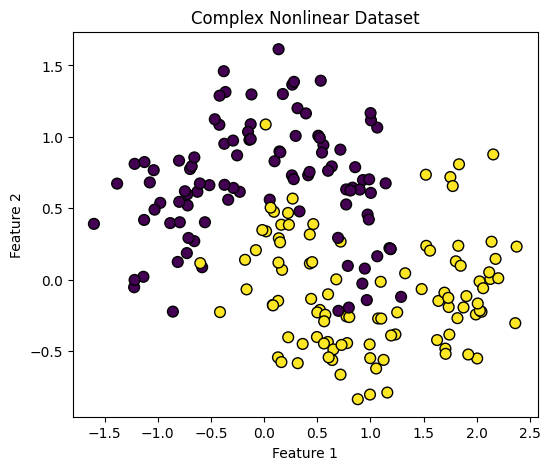

In [ ]:
# =====================================
# Step 1: Import
# =====================================
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# =====================================
# Step 2: Create Complex Dataset
# =====================================
X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

# Visualize dataset
plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:,1], c=y, s=60, edgecolors='k')
plt.title("Complex Nonlinear Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()



In [ ]:
# =====================================
# Step 3: Train-test split
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# =====================================
# Step 4: Linear SVM (will struggle)
# =====================================
linear_svm = SVC(kernel='linear')
linear_svm.fit(X_train, y_train)

y_pred_linear = linear_svm.predict(X_test)
print("Linear SVM Accuracy =", accuracy_score(y_test, y_pred_linear))

# =====================================
# Step 5: RBF Kernel SVM (better)
# =====================================
rbf_svm = SVC(kernel='rbf')
rbf_svm.fit(X_train, y_train)

y_pred_rbf = rbf_svm.predict(X_test)
print("RBF SVM Accuracy =", accuracy_score(y_test, y_pred_rbf))

Linear SVM Accuracy = 0.8333333333333334
RBF SVM Accuracy = 0.9333333333333333


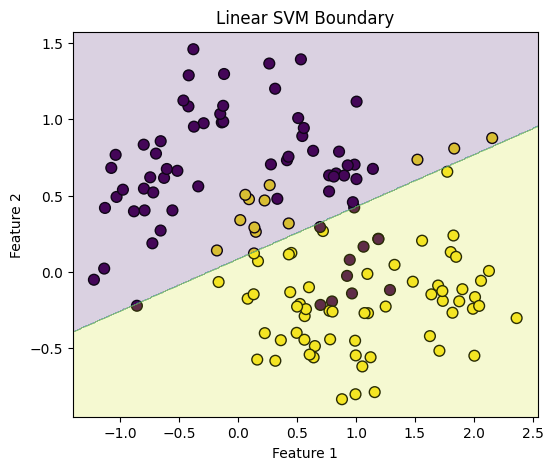

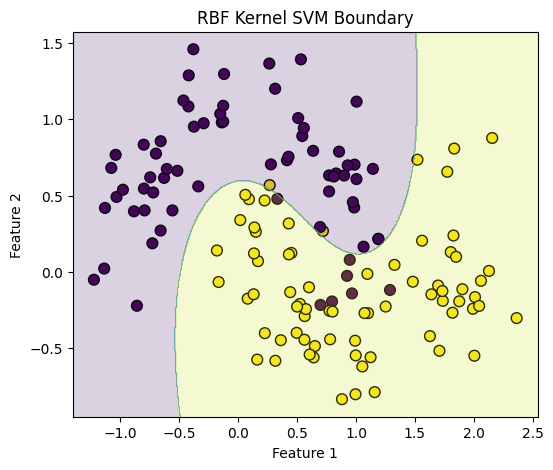

In [ ]:
def plot_boundary(X, y, model, title):
    plt.figure(figsize=(6,5))

    # scatter plot
    plt.scatter(X[:,0], X[:,1], c=y, s=60, edgecolors='k')

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # meshgrid
    xx = np.linspace(xlim[0], xlim[1], 500)
    yy = np.linspace(ylim[0], ylim[1], 500)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    Z = model.predict(xy).reshape(XX.shape)

    plt.contourf(XX, YY, Z, alpha=0.2)

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

# Plot both
plot_boundary(X_train, y_train, linear_svm, "Linear SVM Boundary")
plot_boundary(X_train, y_train, rbf_svm, "RBF Kernel SVM Boundary")

# Start Coding

In [ ]:
print("Hello world")

Hello world


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Dataset/student_performance.csv")
df.head(5)

,student_id,gender,age,study_hours_per_week,attendance_rate,parent_education,internet_access,extracurricular,previous_score,final_score,passed
0,STU0001,Male,15,25,63.8,Bachelor,Yes,Yes,41,67,Yes
1,STU0002,Female,15,2,54.7,Bachelor,Yes,Yes,83,28,No
2,STU0003,Female,19,10,90.5,High School,Yes,No,73,49,No
3,STU0004,Male,16,26,66.8,High School,No,Yes,75,70,Yes
4,STU0005,Female,15,25,73.0,High School,No,Yes,67,77,Yes


# Read Image from Google Drive Folder

**Method 1: Using OpenCV**

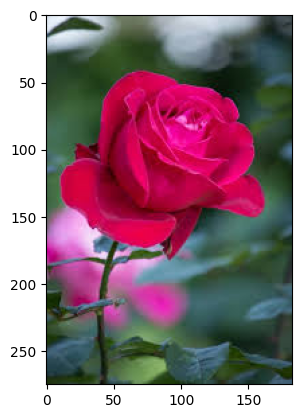

In [ ]:
import cv2
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/Dataset/Flower-2026/1.jpg"
img = cv2.imread(path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
#plt.axis('off')

**Method 2: Using PIL**

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(path)

plt.imshow(img)
plt.axis('off')

# Method 3: Using TensorFlow / Keras

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img = image.load_img(path, target_size=(224, 224))
img_array = image.img_to_array(img)

print(img_array.shape)

# Read Multiple Images (Dataset)

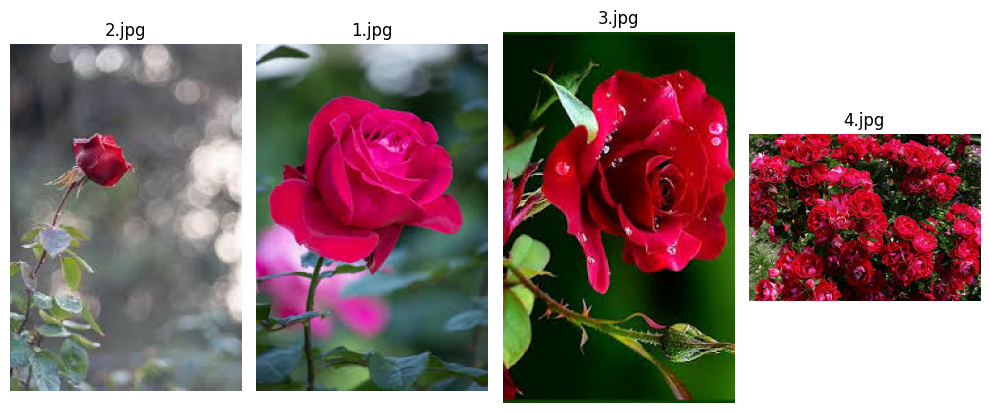

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

folder_path = "/content/drive/MyDrive/Dataset/Flower-2026"

images = []
names = []

# Read images
for file in os.listdir(folder_path):
    if file.endswith(".jpg"):
        img_path = os.path.join(folder_path, file)
        img = cv2.imread(img_path)

        if img is not None:
            images.append(img)
            names.append(file)

# Show images (4 images)
plt.figure(figsize=(10,5))

for i in range(len(images)):   # There are 4 in your case
    img = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)

    plt.subplot(1, len(images), i+1)
    plt.imshow(img)
    plt.title(names[i])
    plt.axis('off')

plt.tight_layout()
plt.show()